# Logistic Regression Baseline for UFC Winner Prediction

This notebook builds a baseline logistic regression model using the processed fight datasets.

In [6]:
# Imports
import warnings
from pathlib import Path

import joblib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

warnings.filterwarnings("ignore")

In [7]:
# Paths
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

train_path = DATA_DIR / "fights_training.csv"
val_path = DATA_DIR / "fights_validation.csv"
test_path = DATA_DIR / "fights_testing.csv"

train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

print(f"Train shape: {train_df.shape}")
print(f"Validation shape: {val_df.shape}")
print(f"Test shape: {test_df.shape}")

Train shape: (7468, 46)
Validation shape: (1066, 46)
Test shape: (2136, 46)


## Build Plan (No Implementation Yet)

Follow these steps to build your logistic regression baseline:

1. Define the prediction target as `winner` and use all remaining columns as features.
2. Split each dataframe into `X` and `y` for train, validation, and test.
3. Verify class balance on the training target (for example, with normalized value counts).
4. Confirm there are no missing values in feature columns before fitting.
5. Build a scikit-learn `Pipeline` with `StandardScaler` then `LogisticRegression`.
6. Fit the pipeline on the training split only.
7. Run predictions and class probabilities on validation and test splits.
8. Compute baseline metrics: accuracy, precision, recall, F1, and ROC-AUC.
9. Print a classification report for both validation and test.
10. Save results to a small metrics table so you can compare future models.

## Define Target Column and the Feature Columns and Split Each Data Frame to X and Y


In [8]:
TARGET = "winner"
features = [col for col in train_df.columns if col != TARGET]

x_train = train_df[features]
y_train = train_df[TARGET]

x_val = val_df[features]
y_val = val_df[TARGET]

x_test = test_df[features]
y_test = test_df[TARGET]

print("X_train:", x_train.shape, "y_train:", y_train.shape)
print("X_val:", x_val.shape, "y_val:", y_val.shape)
print("X_test:", x_test.shape, "y_test:", y_test.shape)

X_train: (7468, 45) y_train: (7468,)
X_val: (1066, 45) y_val: (1066,)
X_test: (2136, 45) y_test: (2136,)


## Build Scikit-Learn Pipline
1. Standarize data to ensure each feature has a mean of zero and a standard deviation of 1 (Standard Scalar)
2. Perform Logistic Regression

In [22]:
pipeline = Pipeline(steps=[("scaler", StandardScaler()),
    ("log_reg", LogisticRegression(random_state=42, max_iter=1000))])
pipeline.fit(x_train, y_train)
val_pred = pipeline.predict(x_val)
val_prob = pipeline.predict_proba(x_val)[:, 1]

# Test predictions
test_pred = pipeline.predict(x_test)
test_prob = pipeline.predict_proba(x_test)[:, 1]

print("Pipeline trained and predictions generated.")

Pipeline trained and predictions generated.


In [26]:
val_metrics = {
    "accuracy": accuracy_score(y_val, val_pred),
    "precision": precision_score(y_val, val_pred, zero_division=0),
    "recall": recall_score(y_val, val_pred, zero_division=0),
    "f1": f1_score(y_val, val_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_val, val_prob),
}

test_metrics = {
    "accuracy": accuracy_score(y_test, test_pred),
    "precision": precision_score(y_test, test_pred, zero_division=0),
    "recall": recall_score(y_test, test_pred, zero_division=0),
    "f1": f1_score(y_test, test_pred, zero_division=0),
    "roc_auc": roc_auc_score(y_test, test_prob),
}

metrics_df = pd.DataFrame([val_metrics, test_metrics], index=["validation", "test"])
display(metrics_df)

print("\nValidation classification report:\"")
print(classification_report(y_val, val_pred, digits=4))

print("\nTest classification report:\"")
print(classification_report(y_test, test_pred, digits=4))

,accuracy,precision,recall,f1,roc_auc
validation,0.572233,0.572233,0.572233,0.572233,0.624357
test,0.622659,0.622659,0.622659,0.622659,0.653159



Validation classification report:"
              precision    recall  f1-score   support

           0     0.5722    0.5722    0.5722       533
           1     0.5722    0.5722    0.5722       533

    accuracy                         0.5722      1066
   macro avg     0.5722    0.5722    0.5722      1066
weighted avg     0.5722    0.5722    0.5722      1066


Test classification report:"
              precision    recall  f1-score   support

           0     0.6227    0.6227    0.6227      1068
           1     0.6227    0.6227    0.6227      1068

    accuracy                         0.6227      2136
   macro avg     0.6227    0.6227    0.6227      2136
weighted avg     0.6227    0.6227    0.6227      2136



## Evaluation Checklist

After training, include the following checks:

1. Plot a confusion matrix on the test set.
2. Inspect top positive and negative coefficients to see which features drive predictions.
3. Compare validation vs test metrics to check for overfitting.
4. Confirm the model performs better than a naive baseline (for example, majority class prediction).
5. Log any weak spots (low recall or precision) for the next iteration.

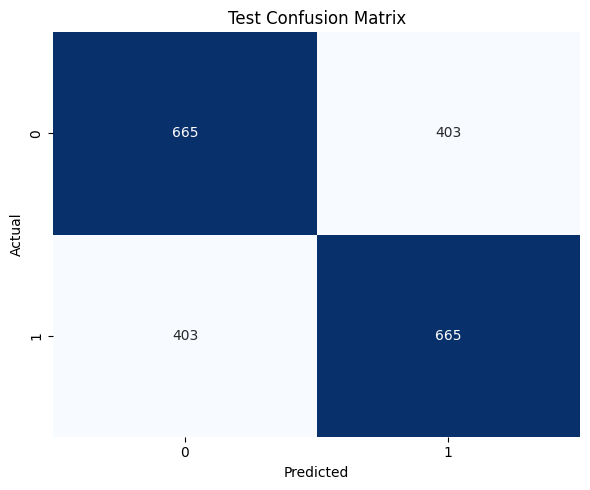

Top 15 features by absolute coefficient:


,feature,coefficient,abs_coef
20,diff_tot_strike_atts,-0.957890,0.957890
21,diff_tot_strikes,0.510566,0.510566
37,diff_ground_atts,0.379732,0.379732
15,diff_fighter_dob,0.319941,0.319941
29,diff_body_strike_atts,0.218704,0.218704
30,diff_body_strikes,-0.216024,0.216024
38,diff_grounds,-0.190193,0.190193
31,diff_leg_strike_atts,0.182702,0.182702
42,diff_losses,-0.168277,0.168277
18,diff_sig_strike_atts,0.159475,0.159475


In [27]:
cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

coef = pipeline.named_steps["log_reg"].coef_[0]
coef_df = pd.DataFrame({"feature": features, "coefficient": coef})
coef_df["abs_coef"] = coef_df["coefficient"].abs()

print("Top 15 features by absolute coefficient:")
display(coef_df.sort_values("abs_coef", ascending=False).head(15))

## Next Improvements After Baseline

Once the baseline is working, iterate in this order:

1. Tune logistic regression hyperparameters (`C`, solver, class weighting).
2. Add cross-validation on the train split for more stable model selection.
3. Add threshold tuning if recall/precision tradeoff matters for your use case.
4. Save the best model artifact into the `models/` directory with versioned names.
5. Track experiment results in a CSV so model performance over time is visible.

In [ ]:
model_path = MODEL_DIR / "logistic_regression_baseline.joblib"
# joblib.dump(pipeline, model_path)
print(f"Saved model to: {model_path}")

Saved model to: /Users/andrewmattei/Machine-Learning-Project/models/logistic_regression_baseline.joblib
